# 04 - Evaluation homework

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import auc, roc_auc_score
from sklearn.feature_extraction import DictVectorizer


In [18]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")


In [19]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [20]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [25]:
df['lead_source'] = df['lead_source'].fillna('NA')
df['industry'] = df['industry'].fillna('NA')
df['employment_status'] = df['employment_status'].fillna('NA')
df['location'] = df['location'].fillna('NA')
df['annual_income'] = df['annual_income'].fillna(0)
df['lead_score'] = df['lead_score'].fillna(0)

categorical = ['lead_source', 'industry', 'employment_status', 'location',]
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [60]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [61]:
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_full_train = df_full_train['converted']
y_train = df_train['converted']
y_val = df_val['converted']
y_test = df_test['converted']

del df_train['converted']
del df_val['converted']
del df_test['converted']

## Question 1

In [26]:
for feature in numerical:
    scores = df_train[feature]
    auc = roc_auc_score(y_train, scores)

    if auc < 0.5:
        scores = -df_train[feature]
        auc = roc_auc_score(y_train, scores)

    print(f'{feature}: {auc:.3f}')

annual_income: 0.608
number_of_courses_viewed: 0.723
interaction_count: 0.765
lead_score: 0.788


## Question 2

In [31]:
dicts_train = df_train[numerical + categorical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(dicts_train)

dicts_val = df_val[numerical + categorical].to_dict(orient='records')

X_val = dv.transform(dicts_val)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)

print(round(auc, 3))

0.732


## Question 3

/tmp/ipykernel_6798/3404581601.py:20: RuntimeWarning: invalid value encountered in scalar divide
  precision.append(tp/(tp + fp))


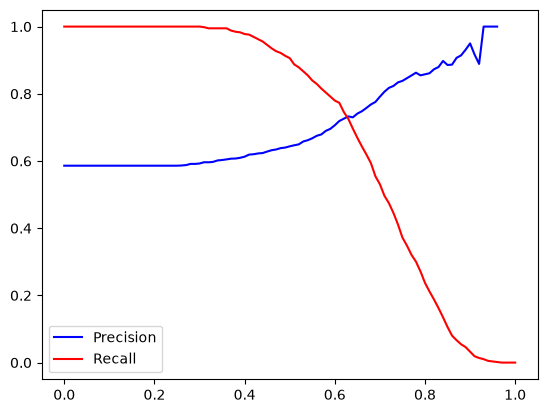

In [ ]:
thresholds = np.linspace(0, 1, 101)

actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

precision = []
recall = []

for t in thresholds:
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    recall.append(tp/(tp+fn))
    precision.append(tp/(tp + fp))


plt.plot(thresholds, precision, 'blue', label='Precision')
plt.plot(thresholds, recall, 'red', label='Recall')
plt.legend()
plt.show()

## Question 4

In [54]:
F1 = []

for t in thresholds:
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    recall = (tp/(tp+fn))
    precision = (tp/(tp + fp))

    F1.append(2*precision*recall/(precision+recall))



F1_max = max(F1)
print(F1_max)
print(F1.index(F1_max)/100)



0.7576158940397352
0.41


/tmp/ipykernel_6798/4025766975.py:14: RuntimeWarning: invalid value encountered in scalar divide
  precision = (tp/(tp + fp))


## Question 5

In [63]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear',C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [64]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [67]:

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train, C=1.0)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print('C=%s %.3f +- %.3f' % (1.0, np.mean(scores), np.std(scores)))

C=1.0 0.732 +- 0.007


## Question 6

In [72]:
for C in [0.000001, 0.001, 1]:

    kfold = KFold(n_splits=5, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f' % (C, np.mean(scores)))

C=1e-06 0.617
C=0.001 0.749
C=1 0.732
